# UZK: готовый автоэнкодер → GRU

Запускайте из корня проекта с ядром `.venv` после `uv sync`.
Сначала обучите и экспортируйте модель в `Test_UZK_Autoencoder.ipynb`.
Конфиг `configs/uzk_autoencoder_gru.yaml` загружает `runs/uzk_encoder.pkl`.

Пайплайн использует сохранённый скейлер и энкодер. Обучается только GRU.
Порядок признаков и частота должны совпадать с запуском автоэнкодера.
Параметры окон входят в экспорт; допустимость периода предобучения проверяет автор эксперимента. Test вычисляется только после обучения GRU.


In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from feature_selector import ExperimentRun, load_config, run_experiment
from feature_selector.artifacts import load_run
from feature_selector.data import load_data
from feature_selector.evaluation import regression_metrics
from feature_selector.visualization import plot_split_predictions, plot_training_history

config = load_config(Path("configs/uzk_autoencoder_gru.yaml"))


## Обучение GRU с готовым энкодером

GRU прогнозирует `UZK.Q.81AY00108.FINALPOINT` на следующий шаг.
Энкодер ранее обучен на всех полных train-окнах признаков, независимо от наличия цели.
GRU обучается только на окнах с известной целью; её скейлер обучается на этих train-целях.
Параметры скейлера признаков и энкодера остаются фиксированными.
Запуск сохраняет всю цепочку, включая загруженную модель, в отдельный каталог.


In [7]:
run = run_experiment(config)
print(f"Results: {run.artifact_dir}")
encoder = run.pipeline["encoder"].artifact_.pipeline["autoencoder"].estimator
pretraining_windows = sum(batch["samples"] for batch in encoder.history_[0]["batches"])
print("Autoencoder train windows (pretraining):", pretraining_windows)
print("GRU train windows:", sum(batch["samples"] for batch in run.model.history_[0]["batches"]))
pd.DataFrame.from_dict(run.metrics, orient="index")


Results: /mnt/data/Projects/feature_selector_v3/runs/20261018T035842739960Z-b72d79c5
Autoencoder train windows (pretraining): 4710
GRU train windows: 222


,mae,rmse,r2,pearson,n,notes
train,4.931091,6.589375,0.909615,0.957217,222,{}
validation,3.509023,4.383673,-0.424082,0.421088,47,{}


## История предобучения энкодера и обучения GRU

История энкодера загружена из файла: это его первоначальное обучение реконструкции
по всем полным окнам признаков. В текущем запуске энкодер не переобучается.
Loss GRU — MSE прогнозирования после масштабирования цели.
Эти величины измеряют разные задачи и не сравниваются между собой.


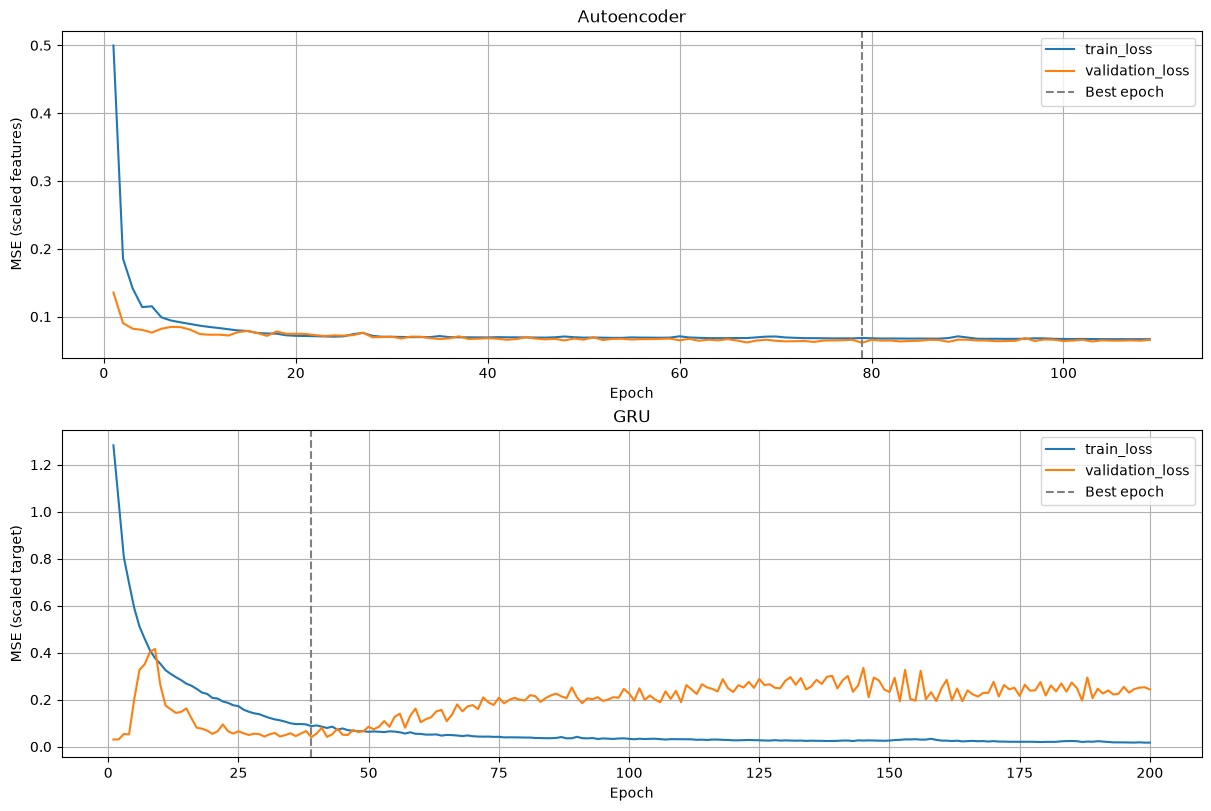

In [8]:
encoder = run.pipeline["encoder"].artifact_.pipeline["autoencoder"].estimator
fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")
plot_training_history(
    encoder.history_, encoder.best_epoch_, ax=axes[0], title="Autoencoder"
)
axes[0].set_ylabel("MSE (scaled features)")
plot_training_history(
    run.model.history_, run.model.best_epoch_, ax=axes[1], title="GRU"
)
axes[1].set_ylabel("MSE (scaled target)")
plt.show()


## Загрузка и явная оценка test

Загружаем сохранённый пайплайн и вычисляем test без дообучения.
Этот вызов не изменяет автоматически сохранённые train/validation-отчёты.


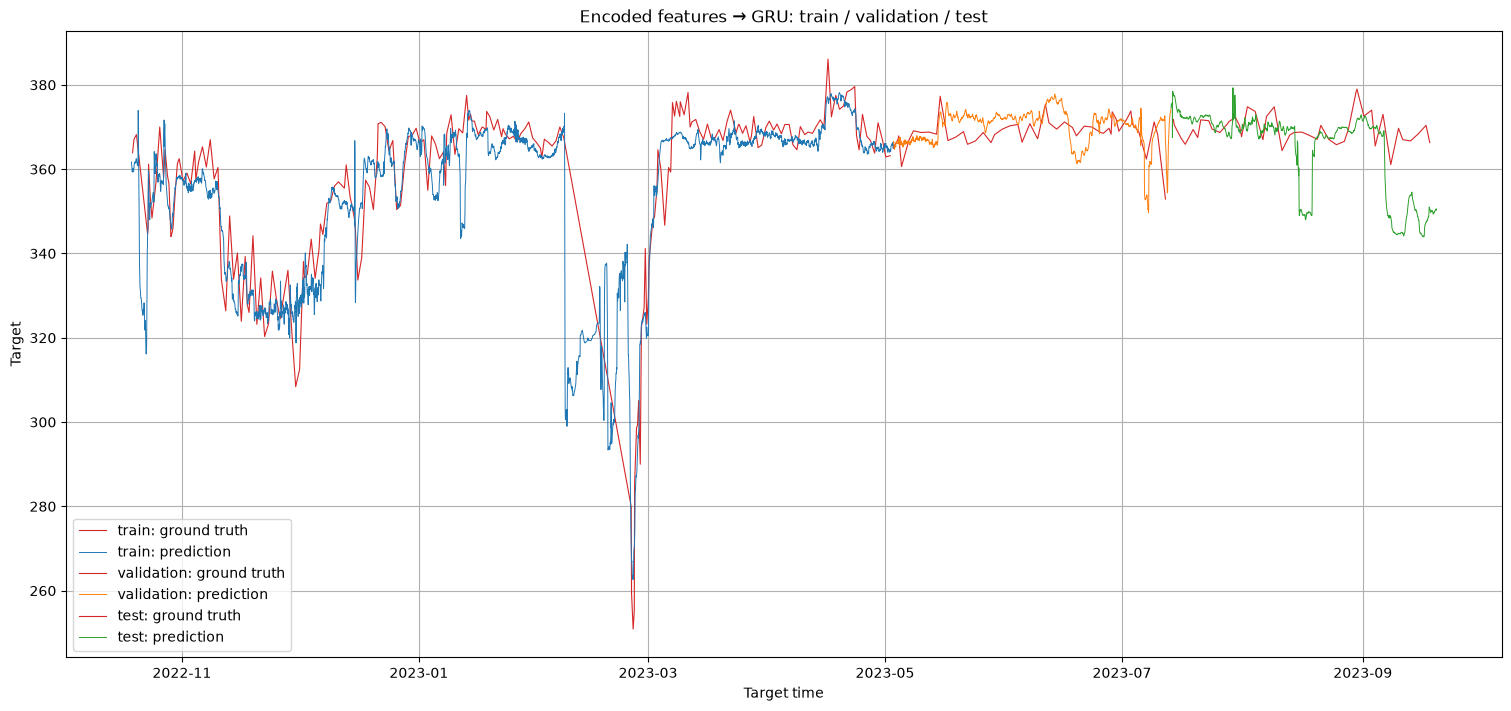

,mae,rmse,r2,pearson,n,notes
train,4.931091,6.589375,0.909615,0.957217,222,{}
validation,3.509023,4.383673,-0.424082,0.421088,47,{}
test,6.306558,9.308300,-6.161623,0.349593,44,{}


In [9]:
saved = load_run(run.artifact_dir)
assert isinstance(saved, ExperimentRun)
data = load_data(**config.data)
test_report = saved.predict(data, split="test")
observed = test_report.dropna(subset=["y_true"])
test_metrics = regression_metrics(observed.y_true, observed.y_pred)
reports = {**run.predictions, "test": test_report}
plot_split_predictions(reports, title="Encoded features → GRU: train / validation / test")
plt.show()
pd.DataFrame.from_dict({**run.metrics, "test": test_metrics}, orient="index")


Batch losses are stored in `history_` and streamed to JSONL and TensorBoard.
Run `tensorboard --logdir runs` to inspect training while it is running.

,epoch,batch,samples,train_loss,step,learning_rate
0,1,1,128,1.432563,1,0.01
1,1,2,94,1.077745,2,0.01
2,2,1,128,1.308734,3,0.01
3,2,2,94,0.678580,4,0.01
4,3,1,128,0.748045,5,0.01


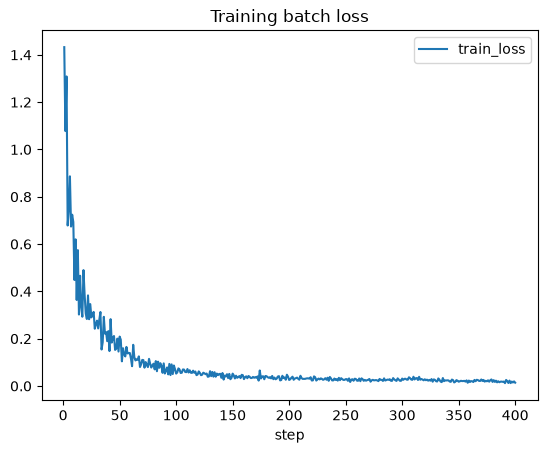

In [10]:
batch_history = pd.DataFrame([
    {"epoch": epoch["epoch"], **batch}
    for epoch in run.model.history_ for batch in epoch["batches"]
])
display(batch_history.head())
if not batch_history.empty:
    batch_history.plot(x="step", y="train_loss", title="Training batch loss")
    plt.show()
